# Лабораторная работа №5, вариант 8

Поразрядная сортировка `uint32` на GPU. Собственное рекурсивное сканирование Blelloch, без Thrust.

Результаты ниже получены для 32, 1 048 576 и предельных 128 000 000 элементов. Численные выводы вычисляются из CSV; исходные замеры и журналы nvprof лежат в `report/results/`.

## Условие и метод

Бинарный вход: `uint32 n`, затем `n` чисел. Выход: только `n` отсортированных чисел, без размера. Ограничение: `n ≤ 128 000 000`.

Для каждого бита от 0 до 31 строятся признаки нуля $z_i$, исключающие префиксы $p_i=\sum_{j<i}z_j$ и число нулей $Z=p_{n-1}+z_{n-1}$. Нулевой бит получает позицию $p_i$, единичный — $Z+i-p_i$.

Сканирование Blelloch обрабатывает фрагменты по `2 × block` элементов, рекурсивно сканирует их суммы и добавляет смещения. Индекс в разделяемой памяти: `i + (i >> 5) + (i >> 10)`. Отступы устраняют конфликты 32 банков и при 1024 нитях.

В основной программе все ядра используют фиксированные `<<<256, 256>>>`. В эксперименте конфигурации меняются явно. CPU — собственная последовательная поразрядная сортировка по байтам (4 прохода), GPU — по битам (32 прохода).

## Подготовка

Запустить notebook из корня репозитория или `lab5-variant8`. Готовые результаты читаются без GPU. Повтор всей серии с профилями:

```bash
python3 -B report/run_benchmarks.py --profile
```

Для каждой конфигурации — **100 прогревов на `min(n, 4096)` элементах**, затем **5 измерений полного массива**. CPU — один прогрев полного массива и 5 измерений. Измеряется сортировка с синхронизацией GPU; выделение памяти, внешние пересылки и проверки исключены. Время отдельных ядер берётся из отдельного запуска nvprof.

In [1]:
import csv
import json
import math
import sys
from html import escape
from pathlib import Path
from IPython.display import HTML, Image, display

current = Path.cwd().resolve()
lab = next((p for p in [current, current / 'lab5-variant8'] if (p / 'lab5.cu').is_file()), None)
if lab is None:
    raise RuntimeError('Откройте notebook из корня репозитория или lab5-variant8.')
sys.dont_write_bytecode = True
sys.path.insert(0, str(lab / 'report'))
from run_benchmarks import CONFIGS, parse_profile
results = lab / 'report/results'

def show_table(headers, rows):
    head = '<tr>' + ''.join(f'<th>{escape(str(h))}</th>' for h in headers) + '</tr>'
    body = ''.join('<tr>' + ''.join(f'<td>{escape(str(v))}</td>' for v in row) + '</tr>' for row in rows)
    display(HTML('<table style="white-space:nowrap">' + head + body + '</table>'))

print('Лабораторная:', lab.name)

Лабораторная: lab5-variant8


## Бинарный пример из ZIP

`int10` извлечён без изменения. Его значения 0–9 имеют одинаковое представление в int32 и uint32. Файлы `uchar10` и `float10` относятся к другим вариантам.

In [2]:
import struct
example = (lab / 'data/int10').read_bytes()
n = struct.unpack_from('<I', example)[0]
values = struct.unpack_from(f'<{n}I', example, 4)
expected = struct.unpack(f'<{n}I', (lab / 'data/uint10.sorted').read_bytes())
assert tuple(sorted(values)) == expected
print('Вход:', *values)
print('Ожидаемый выход:', *expected)
print('Байтов на выходе:', 4 * n, '(без заголовка размера)')

Вход: 0 9 8 7 6 5 4 3 2 1
Ожидаемый выход: 0 1 2 3 4 5 6 7 8 9
Байтов на выходе: 40 (без заголовка размера)


## Проверка результатов и параметров

In [3]:
metadata = json.loads((results / 'metadata.json').read_text())
assert metadata['status'] == 'complete', 'Сначала выполните report/run_benchmarks.py --profile.'
arguments = metadata['arguments']
assert arguments['warmup'] == 100 and arguments['repeats'] == 5
measurements = []
for size in arguments['sizes']:
    with (results / f'benchmark-{size}.csv').open(newline='') as file:
        rows = list(csv.DictReader(file))
    assert [(int(r['grid']), int(r['block'])) for r in rows] == CONFIGS
    for row in rows:
        assert int(row['n']) == size and int(row['errors']) == 0
        assert int(row['warmup']) == 100 and int(row['repeats']) == 5
        assert int(row['warmup_size']) == min(size, arguments['warmup_size'])
        assert int(row['gpu_checks']) == 105 and int(row['cpu_checks']) == 7
        assert all(math.isfinite(float(row[k])) and float(row[k]) > 0 for k in ['cpu_ms', 'gpu_ms', 'speedup'])
        assert math.isclose(float(row['speedup']), float(row['cpu_ms']) / float(row['gpu_ms']), rel_tol=1e-9)
    measurements.extend(rows)
print(f'Проверено: {len(arguments["sizes"])} размера, {len(measurements)} конфигураций GPU.')
print('Прогрев: 100 сортировок на min(n, 4096); измерений полного массива: 5.')

Проверено: 3 размера, 15 конфигураций GPU.
Прогрев: 100 сортировок на min(n, 4096); измерений полного массива: 5.


## Программное и аппаратное обеспечение

In [4]:
show_table(['Параметр', 'Значение'], [
    ['CPU', metadata['cpu_model']],
    ['Логических потоков', metadata['logical_cpus']],
    ['Оперативная память', f'{metadata["ram_kib"] / 2**20:.2f} ГиБ'],
    ['ОС', metadata['platform']],
    ['GPU / драйвер', metadata['gpu_driver']],
    ['nvcc', metadata['nvcc_version'].splitlines()[-1]],
    ['g++', metadata['cxx_version']],
] + [['HDD' if d['rota'] else 'SSD', f'{d["model"].strip()}, {int(d["size"]) / 2**30:.1f} ГиБ'] for d in metadata['disks']])
show_table(['Параметр GPU', 'Значение'], [line.split('\t') for line in metadata['device_info'].strip().splitlines()])

Параметр,Значение
CPU,Intel(R) Core(TM) i7-9750H CPU @ 2.60GHz
Логических потоков,12
Оперативная память,15.50 ГиБ
ОС,Linux-6.8.0-149-generic-x86_64-with-glibc2.35
GPU / драйвер,"NVIDIA GeForce GTX 1050, 570.211.01"
nvcc,Build cuda_12.8.r12.8/compiler.35583870_0
g++,g++ (Ubuntu 11.4.0-1ubuntu1~22.04.3) 11.4.0
HDD,"WDC WD10SPZX-24Z10, 931.5 ГиБ"
SSD,"HFM256GDHTNG-8310A, 238.5 ГиБ"


Параметр GPU,Значение
Модель,NVIDIA GeForce GTX 1050
Compute capability,6.1
CUDA runtime,12080
CUDA driver,12080
"Глобальная память, байт",3158114304
"Разделяемая память на блок, байт",49152
"Константная память, байт",65536
Регистров на блок,65536
Максимум потоков на блок,1024
"Размеры блока (x, y, z)",1024 x 1024 x 64


## Время сортировки и сравнение с CPU

Все времена — **миллисекунды**, среднее пяти измерений. `CPU / GPU > 1` означает преимущество GPU. Для CPU и GPU используется один и тот же исходный массив.

n,Блоков,Нитей,"CPU, мс","GPU, мс",CPU / GPU
32,1,32,0.003,0.261,0.012
32,32,128,0.003,0.261,0.012
32,128,256,0.003,0.275,0.011
32,256,256,0.003,0.305,0.010
32,1024,1024,0.003,1.891,0.002
1048576,1,32,45.020,2016.676,0.022
1048576,32,128,45.020,24.894,1.808
1048576,128,256,45.020,18.183,2.476
1048576,256,256,45.020,17.897,2.515
1048576,1024,1024,45.020,21.599,2.084


n,Лучшая конфигурация,"GPU, мс",CPU / GPU
32,"<<<32, 128>>>",0.261,0.012
1048576,"<<<256, 256>>>",17.897,2.515
128000000,"<<<256, 256>>>",2260.601,0.902


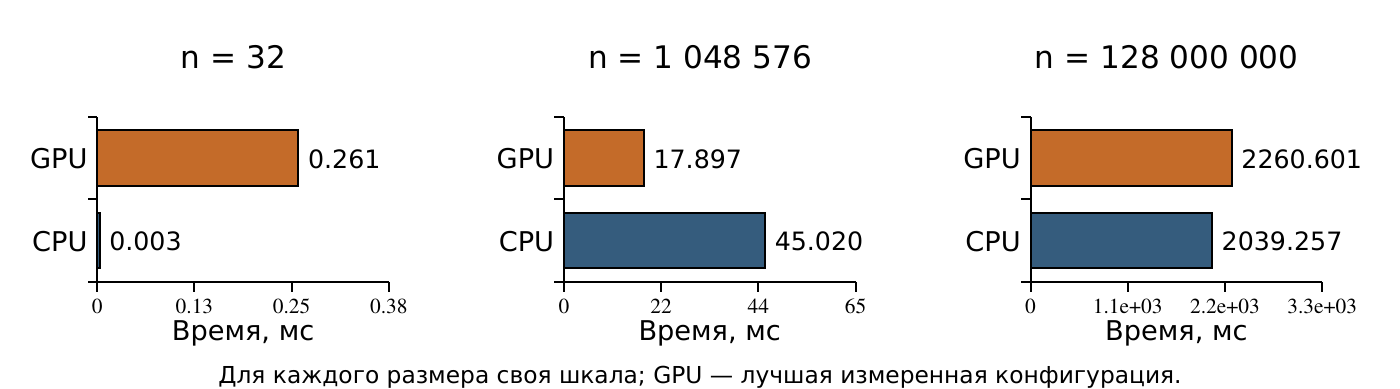

Для каждого размера на графике своя шкала времени; GPU — лучшая измеренная конфигурация.


In [5]:
show_table(['n', 'Блоков', 'Нитей', 'CPU, мс', 'GPU, мс', 'CPU / GPU'],
           [[r['n'], r['grid'], r['block'], f'{float(r["cpu_ms"]):.3f}',
             f'{float(r["gpu_ms"]):.3f}', f'{float(r["speedup"]):.3f}'] for r in measurements])
best_rows = [min((r for r in measurements if int(r['n']) == n), key=lambda r: float(r['gpu_ms']))
             for n in arguments['sizes']]
show_table(['n', 'Лучшая конфигурация', 'GPU, мс', 'CPU / GPU'],
           [[r['n'], f'<<<{r["grid"]}, {r["block"]}>>>', f'{float(r["gpu_ms"]):.3f}',
             f'{float(r["speedup"]):.3f}'] for r in best_rows])
display(Image(filename=str(results / 'comparison.png'), width=900))
print('Для каждого размера на графике своя шкала времени; GPU — лучшая измеренная конфигурация.')

## Время отдельных ядер nvprof

Профилирование выполнено отдельными запусками для завершённых сочетаний размера и конфигурации. Для предельного массива и `<<<1, 32>>>` профиль остановлен после длительного ожидания; время полной сортировки этой конфигурации измерено. Прочерк означает отсутствие завершённого профиля. В область профиля включена одна сортировка полного массива после прогрева. Значения ниже — суммарное время ядра за 32 разряда и все уровни рекурсии. Ноль у `add_offsets` означает отсутствие вызовов на маленьком массиве.

In [6]:
kernel_rows = []
for row in measurements:
    n, grid, block = [int(row[k]) for k in ['n', 'grid', 'block']]
    path = results / f'nvprof-{n}-{grid}-{block}.log'
    if not path.is_file():
        kernel_rows.append([n, grid, block, None, None, None])
        continue
    profile = parse_profile(path.read_text())
    kernels = {r['name']: r for r in profile if r['section'] == 'GPU activities'}
    levels, tiles = 1, (n + 2 * block - 1) // (2 * block)
    while tiles > 1:
        levels += 1
        tiles = (tiles + 2 * block - 1) // (2 * block)
    assert kernels['scan_blocks']['calls'] == 32 * levels
    assert kernels['scatter']['calls'] == 32
    assert kernels.get('add_offsets', {}).get('calls', 0) == 32 * (levels - 1)
    kernel_rows.append([n, grid, block, kernels['scan_blocks']['ms'],
                        kernels.get('add_offsets', {}).get('ms', 0), kernels['scatter']['ms']])
show_table(['n', 'Блоков', 'Нитей', 'scan_blocks, мс', 'add_offsets, мс', 'scatter, мс'],
           [[*r[:3], *[f'{v:.3f}' if v is not None else '—' for v in r[3:]]] for r in kernel_rows])
print(f'Завершённых профилей: {len(metadata["profile_files"])} из {len(measurements)}.')
print('Число вызовов проверено по 32 разрядам и глубине рекурсии для каждого завершённого профиля.')

n,Блоков,Нитей,"scan_blocks, мс","add_offsets, мс","scatter, мс"
32,1,32,0.114,0.000,0.041
32,32,128,0.131,0.000,0.039
32,128,256,0.169,0.000,0.066
32,256,256,0.197,0.000,0.106
32,1024,1024,1.972,0.000,1.400
1048576,1,32,1420.910,310.290,284.140
1048576,32,128,18.661,4.735,5.847
1048576,128,256,11.263,3.853,5.533
1048576,256,256,11.053,3.888,5.527
1048576,1024,1024,14.836,3.760,5.508


Завершённых профилей: 14 из 15.
Число вызовов проверено по 32 разрядам и глубине рекурсии для каждого завершённого профиля.


## CUDA API

Пример для `n = 1 048 576`, конфигурации `<<<256, 256>>>`. Проценты отражают долю **времени**, а не числа вызовов.

In [7]:
profile = parse_profile((results / 'nvprof-1048576-256-256.log').read_text())
api_rows = [r for r in profile if r['section'] == 'API calls']
show_table(['Вызов CUDA API', 'Доля времени, %', 'Время, мс', 'Вызовов'],
           [[r['name'], f'{r["percent"]:.2f}', f'{r["ms"]:.3f}', r['calls']] for r in api_rows])

Вызов CUDA API,"Доля времени, %","Время, мс",Вызовов
cudaDeviceSynchronize,96.52,19.796,1
cudaLaunchKernel,3.38,0.694,192
cudaGetLastError,0.09,0.018,192
cuDeviceGetCount,0.00,0.001,1


## Проверка корректности

В измерительной серии результат GPU побайтно сравнивается с CPU на полном массиве. Ниже сохранённый вывод тестов того же запуска: независимый Python `sorted`, старший бит, повторы, неполные блоки, рекурсивные уровни, пример из ZIP и ошибочный ввод.

In [8]:
for mode in ['cpu', 'gpu']:
    text = metadata['tests'][mode]
    assert 'Все тесты пройдены успешно.' in text
    print(mode.upper() + ':')
    print(text)
print('Ошибки в измерительной серии:', sum(int(r['errors']) for r in measurements))

CPU:
Пройдено тестов: 24 (включая пример из ZIP).
Проверок ошибочного ввода: 6.
Все тесты пройдены успешно.
GPU:
Пройдено тестов: 24 (включая пример из ZIP).
Проверок ошибочного ввода: 6.
Все тесты пройдены успешно.
Ошибки в измерительной серии: 0


## Выводы

Поразрядная сортировка подходит для целочисленных ключей, индексов и группировки записей. Устойчивая перестановка и рекурсивные смещения позволяют обрабатывать произвольную длину массива. Различия между CPU и GPU зависят от числа проходов, объёма данных и конфигурации запуска.

In [9]:
for row in best_rows:
    ratio = float(row['speedup'])
    faster = 'GPU быстрее CPU' if ratio > 1 else 'CPU быстрее GPU'
    print(f'n={row["n"]}: CPU {float(row["cpu_ms"]):.3f} мс, GPU {float(row["gpu_ms"]):.3f} мс; '
          f'<<<{row["grid"]}, {row["block"]}>>>; CPU/GPU={ratio:.3f} — {faster}.')
print(f'Пример из ZIP, {len(measurements)} строк измерений и {len(metadata["profile_files"])} завершённых профилей проверены.')

n=32: CPU 0.003 мс, GPU 0.261 мс; <<<32, 128>>>; CPU/GPU=0.012 — CPU быстрее GPU.
n=1048576: CPU 45.020 мс, GPU 17.897 мс; <<<256, 256>>>; CPU/GPU=2.515 — GPU быстрее CPU.
n=128000000: CPU 2039.257 мс, GPU 2260.601 мс; <<<256, 256>>>; CPU/GPU=0.902 — CPU быстрее GPU.
Пример из ZIP, 15 строк измерений и 14 завершённых профилей проверены.
